##Installing Required Libraries

In this step, we install the libraries and OCR software required to extract text from our Construction Technology and Practices (CTP) lecture PDFs. Some PDFs contain selectable text, while others contain scanned pages where the text is stored as images. We need both PDF text extraction and Optical Character Recognition (OCR) to handle these files.

- **PyMuPDF (`pymupdf`):** Opens PDF files, extracts embedded text, and converts PDF pages into images.
- **pytesseract:** Connects Python to the Tesseract OCR engine to recognize text in images.
- **Pillow (`pillow`):** Loads and processes images before OCR.
- **Tesseract OCR:** The OCR engine that recognizes characters and words from scanned pages.

The commands below install these dependencies in the Google Colab environment. The `!` symbol allows shell commands to run inside a Colab code cell. The `-q` and `-qq` flags reduce installation output, and `-y` automatically confirms installation prompts.

These tools will be used in the next steps to extract text page by page from our lecture PDFs and prepare the raw textual data for the StudyMate domain-adaptive pretraining (DAPT) pipeline.

In [ ]:

!pip -q install pymupdf pytesseract pillow
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 66.6 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


##Connecting Google Drive to Google Colab

In this step, we connect Google Drive to our Colab environment so that Python can access the CTP lecture PDFs stored in our Drive folder.

- **`from google.colab import drive`** imports the Google Colab module used to access Google Drive.
- **`drive.mount("/content/drive")`** mounts Google Drive at the `/content/drive` location, allowing us to read our lecture PDFs and save the extracted datasets directly to Drive.

When this cell is executed, Google Colab may ask for authorization to access Google Drive. Complete the authorization process to continue.

Connecting Drive allows us to access the source PDFs and preserve the extracted DAPT data even after the Colab session ends.

In [ ]:

from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


##Importing Required Python Modules

In this step, we import the Python modules required for PDF processing, OCR, text cleaning, and dataset creation.

- **`pathlib.Path`** – Defines file and folder paths and helps locate the lecture PDFs.
- **`fitz`** – Opens PDF documents, accesses individual pages, extracts embedded text, and renders pages as images.
- **`pytesseract`** – Performs OCR by connecting Python to the Tesseract OCR engine.
- **`json`** – Saves the extracted page data in JSON and JSONL formats.
- **`re`** – Uses regular expressions to clean unwanted whitespace and formatting issues in extracted text.
- **`PIL.Image`** – Loads rendered page images so they can be processed by the OCR engine.
- **`io`** – Handles image data in memory, allowing rendered PDF pages to be passed to the image-processing tools without creating temporary image files.

These modules form the basic toolkit for extracting text from our CTP lecture PDFs, preserving page-level information, and preparing the textual data for the StudyMate DAPT pipeline.

In [ ]:
from pathlib import Path
import fitz
import pytesseract
import json
import re
from PIL import Image
import io

##Locating and Sorting Lecture PDF Files

In this step, we locate all CTP lecture PDFs stored in our Google Drive folder and sort them in numerical order according to their filenames.

- **`pip install natsort`** installs the `natsort` library, which sorts filenames containing numbers in a natural numerical order.
- **`from natsort import natsorted`** imports the function used for natural sorting.
- **`PDF_DIR`** specifies the location of the `ctp` folder in Google Drive.
- **`PDF_DIR.glob("*.pdf")`** finds PDF files directly inside the specified folder.
- **`natsorted(..., key=lambda path: path.name)`** sorts the files by filename, helping maintain the lecture sequence. For example, `Lecture 2.pdf` appears before `Lecture 10.pdf`.
- **The `for` loop** prints each filename so we can verify that the correct PDFs have been located and sorted.

Maintaining the correct order helps us process the lecture materials systematically while preserving each PDF's original filename for source tracking during dataset creation.

In [ ]:
!pip -q install natsort

In [ ]:

from natsort import natsorted
PDF_DIR = Path("/content/drive/MyDrive/ctp")
pdf_files = natsorted(
    PDF_DIR.glob("*.pdf"),
    key=lambda path: path.name
)

for file in pdf_files:
    print(file.name)


1.pdf
2.pdf
3.pdf
4.pdf
5.pdf
6.pdf
7.pdf
8.pdf
9.pdf
10.pdf
11.pdf


In [ ]:
total_pages = 0
for pdf_path in pdf_files:
    pdf = fitz.open(pdf_path)
    page_count = len(pdf)
    total_pages += page_count
    print(f"{pdf_path.name} -> {page_count} pages")
    pdf.close()

print("Total PDF files:", len(pdf_files))
print("Total pages:", total_pages)


1.pdf -> 45 pages
2.pdf -> 42 pages
3.pdf -> 58 pages
4.pdf -> 30 pages
5.pdf -> 34 pages
6.pdf -> 39 pages
7.pdf -> 31 pages
8.pdf -> 22 pages
9.pdf -> 19 pages
10.pdf -> 58 pages
11.pdf -> 28 pages
Total PDF files: 11
Total pages: 406


In [ ]:

# Select the first PDF in our numerical order
pdf_path = pdf_files[2]

# Open the PDF
pdf = fitz.open(pdf_path)

print("File:", pdf_path.name)
print("Number of pages:", len(pdf))

# Extract text from page 1
page = pdf[1]
text = page.get_text("text")

print("\nExtracted text:")
print(text[:2000])

pdf.close()


File: 3.pdf
Number of pages: 58

Extracted text:



In [ ]:
# Open the first PDF
pdf_path = pdf_files[0]
pdf = fitz.open(pdf_path)

# Select the first page
page = pdf[0]

# Check native text extraction
native_text = page.get_text("text")
print("Native text characters:", len(native_text))
print("Native text preview:", repr(native_text[:200]))

# Convert the PDF page into an image
pix = page.get_pixmap(
    matrix=fitz.Matrix(2, 2),
    alpha=False
)

image = Image.open(io.BytesIO(pix.tobytes("png")))

# Run OCR on the image
ocr_text = pytesseract.image_to_string(
    image,
    config="--psm 3"
)

print("\nOCR text characters:", len(ocr_text))
print("OCR text preview:")
print(ocr_text[:2000])

pdf.close()


Native text characters: 0
Native text preview: ''

OCR text characters: 148
OCR text preview:
CIL3050
Construction Technology and Practices

Lecture 1

Sreejith Krishnan

(Some of the images have been used from Internet sources)

31/07/2025




In [ ]:
def clean_text(text):
    # Remove unwanted null characters and extra spaces
    text = text.replace("\x00", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

records = []

for pdf_path in pdf_files:
    print("Processing:", pdf_path.name)
    pdf = fitz.open(pdf_path)

    for page_index, page in enumerate(pdf):
        # First, try extracting embedded text
        native_text = clean_text(page.get_text("text"))

        # Use OCR if very little native text was found
        if len(native_text) < 75:
            pix = page.get_pixmap(
                matrix=fitz.Matrix(2, 2),
                alpha=False
            )

            image = Image.open(
                io.BytesIO(pix.tobytes("png"))
            )

            ocr_text = pytesseract.image_to_string(
                image,
                config="--psm 3"
            )

            text = clean_text(ocr_text)
            method = "ocr" if text else "empty"

        else:
            text = native_text
            method = "native"

        # Save the text together with its source
        records.append({
            "source": pdf_path.name,
            "page": page_index + 1,
            "method": method,
            "text": text
        })

    pdf.close()

print("\nExtraction finished!")
print("Total page records:", len(records))
print("Native pages:", sum(r["method"] == "native" for r in records))
print("OCR pages:", sum(r["method"] == "ocr" for r in records))
print("Empty pages:", sum(r["method"] == "empty" for r in records))


Processing: 1.pdf
Processing: 2.pdf
Processing: 3.pdf
Processing: 4.pdf
Processing: 5.pdf
Processing: 6.pdf
Processing: 7.pdf
Processing: 8.pdf
Processing: 9.pdf
Processing: 10.pdf
Processing: 11.pdf

Extraction finished!
Total page records: 406
Native pages: 0
OCR pages: 405
Empty pages: 1


In [ ]:

for record in records:
    if record["method"] == "empty":
        print("File:", record["source"])
        print("Page:", record["page"])
        print("Characters:", len(record["text"]))


File: 5.pdf
Page: 17
Characters: 0


In [ ]:
import matplotlib.pyplot as plt

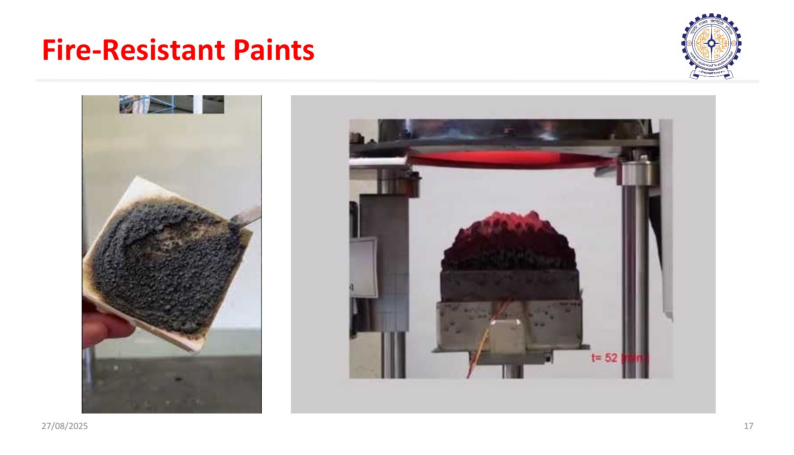

In [ ]:
pdf = fitz.open("/content/drive/MyDrive/ctp/5.pdf")

# Python index 16 = PDF page 17
page = pdf[16]

# Render the page at higher resolution
pix = page.get_pixmap(
    matrix=fitz.Matrix(3, 3),
    alpha=False
)

# Convert rendered PDF image bytes into a PIL image
image = Image.open(io.BytesIO(pix.tobytes("png")))

# Display the page
plt.figure(figsize=(10, 12))
plt.imshow(image)
plt.axis("off")
plt.show()

pdf.close()


In [ ]:

!pip -q install easyocr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 10.0 MB/s eta 0:00:00


In [ ]:
import easyocr
import numpy as np

# Initialize EasyOCR
reader = easyocr.Reader(["en"], gpu=False)

# Find pages with empty extracted text
failed_records = [
    r for r in records
    if not r["text"].strip()
]

print("Pages needing recovery:", len(failed_records))

for record in failed_records:
    pdf_path = PDF_DIR / record["source"]

    with fitz.open(pdf_path) as pdf:
        page = pdf[record["page"] - 1]

        pix = page.get_pixmap(
            matrix=fitz.Matrix(3, 3),
            alpha=False
        )

        image = Image.open(
            io.BytesIO(pix.tobytes("png"))
        ).convert("RGB")

    results = reader.readtext(np.array(image), detail=0)
    recovered_text = clean_text("\n".join(results))

    if recovered_text:
        record["text"] = recovered_text
        record["method"] = "easyocr"

        print(
            f"Recovered: {record['source']} | "
            f"Page {record['page']} | "
            f"Characters: {len(recovered_text)}"
        )
    else:
        print(
            f"Still empty: {record['source']} | "
            f"Page {record['page']}"
        )

Pages needing recovery: 1


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Recovered: 5.pdf | Page 17 | Characters: 52


In [ ]:

# Check pages that may need another OCR attempt

MIN_CHARS = 100

short_records = [
    r for r in records
    if len(r["text"].strip()) < MIN_CHARS
]

print("Total pages:", len(records))
print("Pages with fewer than 100 characters:", len(short_records))

for r in short_records:
    print(
        f"{r['source']} | Page {r['page']} "
        f"| Method: {r['method']} "
        f"| Characters: {len(r['text'].strip())}"
    )


Total pages: 406
Pages with fewer than 100 characters: 59
1.pdf | Page 7 | Method: ocr | Characters: 87
1.pdf | Page 8 | Method: ocr | Characters: 12
1.pdf | Page 9 | Method: ocr | Characters: 42
1.pdf | Page 10 | Method: ocr | Characters: 13
1.pdf | Page 11 | Method: ocr | Characters: 25
1.pdf | Page 12 | Method: ocr | Characters: 14
1.pdf | Page 20 | Method: ocr | Characters: 14
1.pdf | Page 30 | Method: ocr | Characters: 34
1.pdf | Page 38 | Method: ocr | Characters: 76
1.pdf | Page 45 | Method: ocr | Characters: 26
2.pdf | Page 5 | Method: ocr | Characters: 94
2.pdf | Page 7 | Method: ocr | Characters: 92
2.pdf | Page 8 | Method: ocr | Characters: 96
2.pdf | Page 9 | Method: ocr | Characters: 59
2.pdf | Page 13 | Method: ocr | Characters: 77
2.pdf | Page 15 | Method: ocr | Characters: 41
2.pdf | Page 20 | Method: ocr | Characters: 89
2.pdf | Page 26 | Method: ocr | Characters: 93
2.pdf | Page 29 | Method: ocr | Characters: 28
2.pdf | Page 31 | Method: ocr | Characters: 97
2.pdf | P

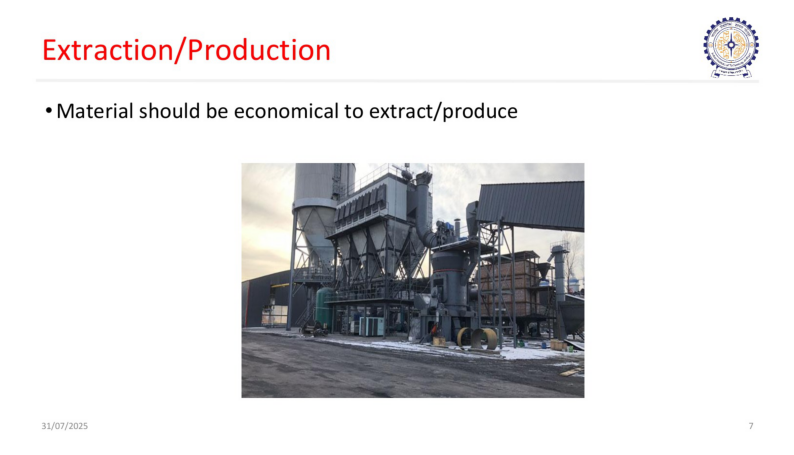

In [ ]:
pdf = fitz.open("/content/drive/MyDrive/ctp/1.pdf")

# Python index 6 = PDF page 7
page = pdf[6]

# Render the page at higher resolution
pix = page.get_pixmap(
    matrix=fitz.Matrix(3, 3),
    alpha=False
)

# Convert rendered PDF image bytes into a PIL image
image = Image.open(io.BytesIO(pix.tobytes("png")))

# Display the page
plt.figure(figsize=(10, 12))
plt.imshow(image)
plt.axis("off")
plt.show()

pdf.close()


In [ ]:
import re

def assess_text(text):
    text = text.strip()

    if not text:
        return "EMPTY"

    # Count letters and numbers
    useful_chars = sum(ch.isalnum() for ch in text)
    useful_ratio = useful_chars / len(text)

    # Detect long sequences of unusual symbols
    suspicious_symbols = len(re.findall(r"[^a-zA-Z0-9\s.,:;()/%+\-]", text))
    symbol_ratio = suspicious_symbols / len(text)

    if len(text) < 30:
        return "SHORT"

    if useful_ratio < 0.45 or symbol_ratio > 0.20:
        return "REVIEW"

    return "OK"


for r in records:
    r["quality_flag"] = assess_text(r["text"])

from collections import Counter

print(Counter(r["quality_flag"] for r in records))

print("\nPages flagged for review:")
for r in records:
    if r["quality_flag"] in ["EMPTY", "REVIEW"]:
        print(
            f"{r['source']} | Page {r['page']} | "
            f"{r['quality_flag']} | "
            f"{len(r['text'])} characters"
        )

Counter({'OK': 384, 'SHORT': 21, 'REVIEW': 1})

Pages flagged for review:
6.pdf | Page 15 | REVIEW | 31 characters


Source: 6.pdf
Page: 15
Method: ocr
Characters: 31
Extracted text:
'jd\nW)\nod)\njad\n~\n=\np=)\nYO\n—)\nan)'


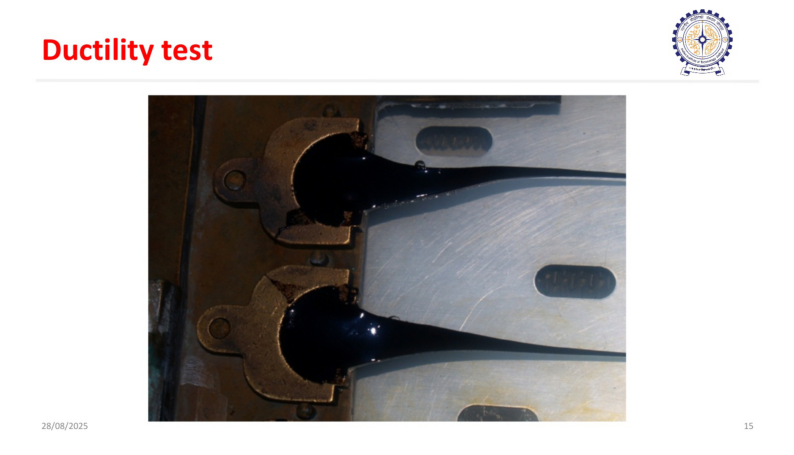

In [ ]:
for r in records:
    if r["source"] == "6.pdf" and r["page"] == 15:
        print("Source:", r["source"])
        print("Page:", r["page"])
        print("Method:", r["method"])
        print("Characters:", len(r["text"]))
        print("Extracted text:")
        print(repr(r["text"]))
pdf = fitz.open("/content/drive/MyDrive/ctp/6.pdf")

page = pdf[14]

# Render the page at higher resolution
pix = page.get_pixmap(
    matrix=fitz.Matrix(3, 3),
    alpha=False
)

# Convert rendered PDF image bytes into a PIL image
image = Image.open(io.BytesIO(pix.tobytes("png")))

# Display the page
plt.figure(figsize=(10, 12))
plt.imshow(image)
plt.axis("off")
plt.show()

pdf.close()




In [ ]:


reader = easyocr.Reader(["en"], gpu=False)

pdf_path = PDF_DIR / "6.pdf"

with fitz.open(pdf_path) as pdf:
    page = pdf[14]  # Page 15

    pix = page.get_pixmap(
        matrix=fitz.Matrix(3, 3),
        alpha=False
    )

    image = Image.open(
        io.BytesIO(pix.tobytes("png"))
    ).convert("RGB")

results = reader.readtext(np.array(image), detail=0)
recovered_text = clean_text("\n".join(results))

print("EasyOCR output:")
print(recovered_text)

# Update the existing record
for r in records:
    if r["source"] == "6.pdf" and r["page"] == 15:
        if recovered_text:
            r["text"] = recovered_text
            r["method"] = "easyocr"
        print("\nUpdated record:")
        print(r)
        break

EasyOCR output:
Ductility test
#trr
Fj [
28/08/2025
15
Txinme

Updated record:
{'source': '6.pdf', 'page': 15, 'method': 'easyocr', 'text': 'Ductility test\n#trr\nFj [\n28/08/2025\n15\nTxinme', 'quality_flag': 'REVIEW'}


In [ ]:
TARGET_CHARS = 2000

chunks = []
current_pages = []
current_length = 0

for r in records:
    text = r["text"].strip()

    # Skip only pages with no extracted text
    if not text:
        continue

    page_info = {
        "source": r["source"],
        "page": r["page"],
        "text": text
    }

    # Start a new chunk if adding this page exceeds the target
    if current_pages and current_length + len(text) > TARGET_CHARS:
        chunks.append({
            "text": "\n\n".join(
                p["text"] for p in current_pages
            ),
            "sources": [
                {
                    "source": p["source"],
                    "page": p["page"]
                }
                for p in current_pages
            ]
        })

        current_pages = []
        current_length = 0

    current_pages.append(page_info)
    current_length += len(text)

# Add the final chunk
if current_pages:
    chunks.append({
        "text": "\n\n".join(
            p["text"] for p in current_pages
        ),
        "sources": [
            {
                "source": p["source"],
                "page": p["page"]
            }
            for p in current_pages
        ]
    })

print("Total page records:", len(records))
print("Total non-empty pages:", sum(bool(r["text"].strip()) for r in records))
print("Total chunks:", len(chunks))
print("First chunk characters:", len(chunks[0]["text"]) if chunks else 0)

Total page records: 406
Total non-empty pages: 406
Total chunks: 65
First chunk characters: 1793


In [ ]:
for i, chunk in enumerate(chunks[:3]):
    print("\n" + "=" * 70)
    print(f"Chunk {i + 1}")
    print("Characters:", len(chunk["text"]))
    print("Sources:", chunk["sources"])
    print("\nText preview:")
    print(chunk["text"][:1000])


Chunk 1
Characters: 1793
Sources: [{'source': '1.pdf', 'page': 1}, {'source': '1.pdf', 'page': 2}, {'source': '1.pdf', 'page': 3}, {'source': '1.pdf', 'page': 4}, {'source': '1.pdf', 'page': 5}, {'source': '1.pdf', 'page': 6}, {'source': '1.pdf', 'page': 7}, {'source': '1.pdf', 'page': 8}, {'source': '1.pdf', 'page': 9}, {'source': '1.pdf', 'page': 10}, {'source': '1.pdf', 'page': 11}, {'source': '1.pdf', 'page': 12}, {'source': '1.pdf', 'page': 13}, {'source': '1.pdf', 'page': 14}]

Text preview:
CIL3050
Construction Technology and Practices

Lecture 1

Sreejith Krishnan

(Some of the images have been used from Internet sources)

31/07/2025

Course Policies

¢e Attendance — Minimum 75% attendance

¢ Grading Policy —
¢ Lecture Component (80 Marks) + Lab Component (20 Marks)
¢ Major — 40 Marks
¢ Minor — 20 Marks
¢ Assignment — 10 Marks
* Quizzes — 10 Marks

¢ Classes start on time
¢ Please switch off or put your mobile phones in silent mode

¢ What are the commonly used construction ma

In [ ]:
import re

print("Total chunks:", len(chunks))

for i, chunk in enumerate(chunks):
    text = chunk["text"]

    # Count letters and numbers
    useful_chars = sum(c.isalnum() for c in text)
    useful_ratio = useful_chars / len(text) if text else 0

    # Find suspicious repeated symbols
    suspicious = re.findall(
        r"[^\w\s.,:;()/%+\-]{3,}",
        text
    )

    print(
        f"Chunk {i + 1} | "
        f"Characters: {len(text)} | "
        f"Alphanumeric ratio: {useful_ratio:.2f} | "
        f"Suspicious sequences: {len(suspicious)}"
    )

Total chunks: 65
Chunk 1 | Characters: 1793 | Alphanumeric ratio: 0.75 | Suspicious sequences: 0
Chunk 2 | Characters: 1469 | Alphanumeric ratio: 0.78 | Suspicious sequences: 0
Chunk 3 | Characters: 1964 | Alphanumeric ratio: 0.80 | Suspicious sequences: 0
Chunk 4 | Characters: 1564 | Alphanumeric ratio: 0.79 | Suspicious sequences: 0
Chunk 5 | Characters: 1813 | Alphanumeric ratio: 0.75 | Suspicious sequences: 0
Chunk 6 | Characters: 1980 | Alphanumeric ratio: 0.78 | Suspicious sequences: 0
Chunk 7 | Characters: 1083 | Alphanumeric ratio: 0.76 | Suspicious sequences: 0
Chunk 8 | Characters: 1989 | Alphanumeric ratio: 0.77 | Suspicious sequences: 0
Chunk 9 | Characters: 1999 | Alphanumeric ratio: 0.74 | Suspicious sequences: 0
Chunk 10 | Characters: 1852 | Alphanumeric ratio: 0.73 | Suspicious sequences: 0
Chunk 11 | Characters: 1858 | Alphanumeric ratio: 0.75 | Suspicious sequences: 0
Chunk 12 | Characters: 1876 | Alphanumeric ratio: 0.75 | Suspicious sequences: 0
Chunk 13 | Character

In [ ]:
import re

for i, chunk in enumerate(chunks):
    text = chunk["text"]

    suspicious = re.findall(
        r"[^\w\s.,:;()/%+\-]{3,}",
        text
    )

    if suspicious or len(text) < 500:
        print("\n" + "=" * 70)
        print("Chunk:", i + 1)
        print("Characters:", len(text))
        print("Sources:", chunk["sources"])
        print("Suspicious sequences:", suspicious)
        print("\nText:")
        print(text)


Chunk: 15
Characters: 1834
Sources: [{'source': '3.pdf', 'page': 16}, {'source': '3.pdf', 'page': 17}, {'source': '3.pdf', 'page': 18}, {'source': '3.pdf', 'page': 19}, {'source': '3.pdf', 'page': 20}]
Suspicious sequences: ['!!!']

Text:
¢ Unburnt carbon in fly ash can have
a negative effect for cementitious
applications
¢ Increased water demand
¢ Reduced workability

*Can potentially affect the strength
characteristics

¢ Highly undesirable!!!

¢What would be a simple test to
estimate the unburnt carbon
content in Fly Ash?

(Goodzari and Sanei, 2009)

12/08/2025 IIT Jodhpur 17

Fly Ash — Production

¢In addition to the type of coal, other parameters that can affect the FA
characteristics —

¢ Method of burning coal
* Combustion equipment available in the plant
* Collection process used in the plant

Thought Exercises

¢ What are the practical implications of these parameters on fly ash
generated at different power plants?

¢What could be some practical implications of particle shape

In [ ]:
for r in records:
    if r["source"] == "3.pdf" and 21 <= r["page"] <= 26:
        print("\n" + "=" * 60)
        print(f"Page: {r['page']} | Method: {r['method']}")
        print(f"Characters: {len(r['text'])}")
        print(r["text"][:1200])


Page: 21 | Method: ocr
Characters: 203
Physical Properties

¢ Specific gravity 1.9 to 2.8

* Bulk density 0.54 g/cm? to 1.5 g/cm?

(https://solidwaste.alpapowder.com/rapid-identification

12/08/2025 lIT Jodhpur -method-of-fly-ash-quality/) 22

Page: 22 | Method: ocr
Characters: 491
pe
~
eT)
oD)
Shxn
~
Vv)
i)
Zz
Vv)
WY)
LD)
Seon
©.
=
oe)
O
S
Oo
i on
Vv)
4°)
=
=
Gq
Oo
~
O
wv
Ge
LL

—)
vo)

S S
Ta) +

CLLLLLLLLSSSLSSSTSSSS SS SS 474,
Ey

PURERREADEUDEREAGEUUEDEREOUTUUEEEEEEATEUEL
YSLLLSLTTTISISITISISITS ILA,
EXC ss

POREUAUEUTEEAUEAU EE EEEU EET EE UTERINE
Kiiiiiddliddiddddddddddddd
RM gy

S i) —) i)

foe) AN a

(eq) WSuans datssaiduiod

¢ The addi

ion of fly ash improves
ive strength of the

the compress

concrete

Fly ash (%)

(Siddique and Khan)

23

5

12/08/202

Page: 23 | Method: ocr
Characters: 183
FA — Portlandite Content

12/08/2025

b)

Portlandite [g/100g OPC]

28
26
24

—a4— OPC
—e— OPC-Qz
—a— OPC-F1

— OPC-F2
- -o--OPC-F1-L

0.1 1 10 100
Time [d]

(Deschner et al 2012)

24


In [ ]:
import json

output_path = PDF_DIR / "dapt_chunks.jsonl"

with output_path.open("w", encoding="utf-8") as f:
    for chunk in chunks:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

print("Saved chunks:", len(chunks))
print("Output file:", output_path)

Saved chunks: 65
Output file: /content/drive/MyDrive/ctp/dapt_chunks.jsonl


In [ ]:
# import json

# output_path = PDF_DIR / "dapt_chunks.jsonl"

# loaded_chunks = []

# with output_path.open("r", encoding="utf-8") as f:
#     for line_number, line in enumerate(f, start=1):
#         chunk = json.loads(line)

#         # Check required fields
#         assert "text" in chunk, f"Missing text in line {line_number}"
#         assert "sources" in chunk, f"Missing sources in line {line_number}"
#         assert isinstance(chunk["text"], str)
#         assert chunk["text"].strip(), f"Empty chunk in line {line_number}"
#         assert chunk["sources"], f"Missing sources in line {line_number}"

#         loaded_chunks.append(chunk)

# print("File validation passed!")
# print("Chunks loaded:", len(loaded_chunks))
# print("Total characters:", sum(len(c["text"]) for c in loaded_chunks))
# print("First chunk source:", loaded_chunks[0]["sources"])

File validation passed!
Chunks loaded: 65
Total characters: 116331
First chunk source: [{'source': '1.pdf', 'page': 1}, {'source': '1.pdf', 'page': 2}, {'source': '1.pdf', 'page': 3}, {'source': '1.pdf', 'page': 4}, {'source': '1.pdf', 'page': 5}, {'source': '1.pdf', 'page': 6}, {'source': '1.pdf', 'page': 7}, {'source': '1.pdf', 'page': 8}, {'source': '1.pdf', 'page': 9}, {'source': '1.pdf', 'page': 10}, {'source': '1.pdf', 'page': 11}, {'source': '1.pdf', 'page': 12}, {'source': '1.pdf', 'page': 13}, {'source': '1.pdf', 'page': 14}]
